# Prédire l'arousal : features riches, EEG et modèles robustes (version 5)

Les versions 1 à 4 plafonnent vers **0,59 d'AUC** sur des participants jamais vus, quelle que soit la méthode (CCA, autoencodeur, optimisation). La conclusion de la v4 : la limite vient des **entrées** (12 résumés sur les 10 premières secondes), pas du modèle. Ce notebook change donc les entrées, avec les méthodes qui marchent le mieux dans la littérature sur les signaux physiologiques :

| Levier | Ce qui change | Pourquoi |
| --- | --- | --- |
| **Fenêtre** | toute la vidéo (plafonnée à `MAX_WINDOW_S`) au lieu des 10 premières secondes | la note d'arousal porte sur toute la vidéo |
| **Cœur** | 8 mesures : fréquence (moyenne, dispersion, étendue, pente), variabilité (SDNN, RMSSD, pNN50), changement | mesures classiques de variabilité cardiaque |
| **Peau** | 9 mesures : niveau lent (tonique) et **réactions rapides (phasiques)** : nombre de réactions par minute, amplitude, aire, latence | la peau est le meilleur marqueur physiologique de l'arousal |
| **Respiration** | 6 mesures : rythme, régularité, amplitude, changements | |
| **Pupille** | 6 mesures : dilatation précoce, tardive, maximale, variabilité, pente | |
| **EEG** | puissance (log) en thêta, alpha, bêta, gamma dans 7 régions du cuir chevelu, asymétrie alpha frontale, rapport thêta/bêta frontal (30 mesures) | le log de la puissance est l'« entropie différentielle », la feature EEG la plus utilisée pour l'émotion |
| **Modèles** | régression logistique, forêt aléatoire, gradient boosting, et leur **ensemble** (moyenne des probabilités) | les arbres captent des effets non linéaires ; l'ensemble est plus stable |

**Leçon de la v4 appliquée ici :** chercher les réglages sur 20 participants a fait *baisser* les scores (le choix s'adapte au bruit). Tous les réglages des modèles sont donc **fixés à l'avance**, à des valeurs standard et prudentes, et le **modèle principal est déclaré avant de regarder les résultats** : l'ensemble sur corps + EEG.

**Même protocole qu'avant :** un participant mis de côté à chaque pli (LOPO), cible = arousal au-dessus de la médiane du participant, AUC (mesure principale) et balanced accuracy. La référence à battre est recalculée sur les mêmes essais : les 12 résumés de la v4 avec une régression logistique.

**Avant de lancer :** même installation que la v3. Pas de `torch` nécessaire, pas de GPU. La première lecture des fichiers est plus longue qu'avant (l'EEG est lu) ; elle est ensuite gardée en cache.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pyedflib
from IPython.display import display
from scipy.signal import butter, find_peaks, sosfiltfilt, welch
from scipy.stats import wilcoxon
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.utils.class_weight import compute_sample_weight

cwd = Path.cwd().resolve()
if (cwd / "starting_notebooks" / "bdf_loader.py").is_file():
    ROOT = cwd
elif cwd.name == "starting_notebooks" and (cwd / "bdf_loader.py").is_file():
    ROOT = cwd.parent
else:
    raise RuntimeError("Lancer le noyau depuis la racine du repo ou depuis starting_notebooks/.")
if str(ROOT / "starting_notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "starting_notebooks"))
from bdf_loader import uV_to_uS

mne.set_log_level("ERROR")

## 1 · Réglages et participants

`PARTICIPANT_IDS = None` utilise tous les participants téléchargés. Pour en ajouter, mettre `DOWNLOAD_N` à un nombre (par exemple 25) et lancer la cellule : elle choisit au hasard, avec une graine fixe, des participants qui ont au moins 20 notes d'arousal au jour 1, en excluant les participants de test et ceux déjà présents. Environ 220 Mo par participant. Remettre ensuite `DOWNLOAD_N = 0`.

In [2]:
DATA_ROOT = ROOT / "sample"
BDF_ROOT = DATA_ROOT / "PREPROCESSED"
TRIAL_S = 10.0          # fenêtre analysée après le début de la vidéo (s)
BASELINE_S = 2.0        # référence avant la vidéo (s)
MIN_TRIALS = 10         # bons essais minimum par participant
MAX_WINDOW_S = 120      # fenêtre « vidéo entière », plafonnée (s) ; None = toute la vidéo
MIN_WINDOW_S = 10       # vidéos plus courtes ignorées (s)
USE_EEG = True          # False : seulement les signaux du corps (lecture bien plus rapide)
N_JOBS = -1             # cœurs pour la forêt aléatoire (calcul par fils, sans souci sous Windows)
PARTICIPANT_IDS = None  # None : tous les participants téléchargés
USE_CACHE = True        # garde les résumés calculés dans sample/features_cache/ (relances bien plus rapides)
DOWNLOAD_N = 0          # >0 : télécharge ce nombre de participants en plus (via download_participants.py)
DOWNLOAD_SEED = 42

labels_path = DATA_ROOT / "labels_train.csv"
if not labels_path.is_file():
    raise FileNotFoundError(f"Télécharger labels_train.csv dans {DATA_ROOT}.")
labels = pd.read_csv(labels_path, na_values=["TESTSUBJECT"], usecols=[
    "cohort", "participant_id", "day", "start_marker", "rating_arousal"])
labels["participant_id"] = labels["participant_id"].astype(str).str.strip()
labels["day"] = pd.to_numeric(labels["day"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
labels["start_marker"] = pd.to_numeric(labels["start_marker"], errors="coerce")
labels["rating_arousal"] = pd.to_numeric(labels["rating_arousal"], errors="coerce")
labels = labels.dropna(subset=["day", "start_marker"])
labels[["day", "start_marker"]] = labels[["day", "start_marker"]].astype(int)
keys = ["participant_id", "day", "start_marker"]
if labels.duplicated(keys).any():
    raise ValueError("Marqueurs ambigus dans labels_train.csv.")


def downloaded_ids():
    found = BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf")
    return {path.parent.name for path in found}


if DOWNLOAD_N > 0:
    # Même téléchargement que download_participants.py (à la racine du repo), fichier par fichier, peu de mémoire.
    import subprocess
    script = ROOT / "download_participants.py"
    if not script.is_file():
        raise FileNotFoundError(f"Mettre download_participants.py dans {ROOT}.")
    subprocess.run([sys.executable, str(script), "--n", str(DOWNLOAD_N), "--seed", str(DOWNLOAD_SEED),
                    "--data-root", str(DATA_ROOT)], check=True, cwd=ROOT)

available_bdfs = sorted(BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf"))
if PARTICIPANT_IDS is not None:
    by_id = {bdf.parent.name: bdf for bdf in available_bdfs}
    missing = sorted(set(PARTICIPANT_IDS) - set(by_id))
    if missing:
        raise FileNotFoundError(f"Fichiers manquants : {missing}")
    available_bdfs = [by_id[p] for p in PARTICIPANT_IDS]
bdfs = available_bdfs
if not bdfs:
    raise FileNotFoundError(f"Aucun fichier emotion-video du jour 1 dans {BDF_ROOT}.")

marker_key = pd.read_csv(ROOT / "starting_notebooks" / "markers.csv")
video_key = marker_key.loc[marker_key["Start Marker"] >= 10100].set_index("Start Marker")
end_marker = video_key["End Marker"].to_dict()

selected = [bdf.parent.name for bdf in bdfs]
cohorts = labels.loc[labels.participant_id.isin(selected)].groupby("participant_id").cohort.first()
print(f"{len(bdfs)} enregistrements sélectionnés : {', '.join(selected)}")
print("Participants par cohorte :", cohorts.value_counts().sort_index().to_dict())

26 enregistrements sélectionnés : P001, P017, P020, P026, P086, P090, P097, P124, P126, P128, P129, P131, P137, P138, P174, P186, P187, P189, P194, P201, P217, P219, P308, P310, P367, P459
Participants par cohorte : {1: 14, 2: 8, 3: 2, 4: 1, 5: 1}


## 2 · Lire les signaux et calculer les features

Pour chaque vidéo, trois jeux de features sont calculés :

- **Référence** (`ref_…`) : exactement les 12 résumés des versions 1 à 4 (10 premières secondes).
- **Corps enrichi** : les 29 mesures du tableau du haut, sur **toute la vidéo** (`ecg_…`, `eda_…`, `resp_…`, `pup_…`) et, pour mesurer l'effet de la fenêtre seule, sur les **10 premières secondes** (`w10_…`).
- **EEG** (`eeg_…`) : 30 mesures, sur toute la vidéo.

Les signaux du corps se lisent comme avant. L'EEG est lu vidéo par vidéo, sans charger tout l'enregistrement en mémoire. La puissance par bande est calculée par la méthode de Welch (fenêtres de 2 s), puis moyennée sur les électrodes de chaque région par la médiane, ce qui résiste à une électrode défaillante.

**Contrôles qualité :** les mêmes qu'avant (battements plausibles, peau ni plate ni saturée, au moins 60 % de mesures valides pour la pupille). Une feature qui échoue reste vide et sera remplacée par la moyenne du participant (section 3), au lieu de supprimer tout l'essai.

In [3]:
MODALITY_COLS = {
    "ECG": ["ecg_hr", "ecg_rr_sd", "ecg_hr_change"],
    "GSR": ["gsr_mean_delta", "gsr_max_delta", "gsr_slope"],
    "RESP": ["resp_rate", "resp_amp", "resp_level_delta"],
    "PUPIL": ["pup_mean_delta", "pup_max_delta", "pup_slope"],
}
PUPIL_VALID_MM = (1.5, 9.0)   # diamètres plausibles (mm) ; le reste = clignement ou perte
PUPIL_GRID_HZ = 50            # grille de rééchantillonnage de la pupille


def read_signals(bdf):
    # Lit cœur, peau, respiration (1 kHz) et pupille (temps et valeurs) d'un enregistrement.
    record_map = json.loads(bdf.with_suffix(".record_map").read_text(encoding="utf-8"))
    groups = [spec for stream in record_map["stream_map"].values() for spec in stream.values()]
    with pyedflib.EdfReader(str(bdf)) as reader:
        names = reader.getSignalLabels()
        for needed in ["ECG", "GSR", "Resp", "pupildiameter_le", "pupildiameter_ri"]:
            if needed not in names:
                raise ValueError(f"Canal {needed} absent de {bdf.name}.")
        ecg_id, gsr_id, resp_id = names.index("ECG"), names.index("GSR"), names.index("Resp")
        fs = reader.getSampleFrequency(ecg_id)
        n_samples = reader.getNSamples()
        total = record_map.get("TotalSamples")
        n_master = int(min(n_samples[ecg_id], total)) if isinstance(total, int) and total > 0 else int(n_samples[ecg_id])
        ecg = reader.readSignal(ecg_id, 0, n_master)
        gsr_uV = reader.readSignal(gsr_id, 0, n_master)
        resp = reader.readSignal(resp_id, 0, n_master)

        # Pupille : même alignement que bdf_loader.load_bdf.
        gaze = [g for g in groups if g.get("correction", {}).get("RecordType", "").lower() == "oculometry"][0]
        correction = gaze["correction"]
        gaze_rate = float(correction.get("EffectiveSamplingFrequency", correction.get("SamplingFrequency")))
        onset = float(correction.get("OnsetSeconds", 0.0))
        native_count = round(n_master * gaze_rate / fs)
        onset_idx = min(max(round(onset * fs), 0), n_master - 1)
        filler = round(onset * gaze_rate)
        rows = np.round(np.linspace(onset_idx, n_master - 1, native_count - filler)).astype(int)
        eyes = []
        for name in ["pupildiameter_le", "pupildiameter_ri"]:
            idx = names.index(name)
            packed = reader.readSignal(idx, 0, min(native_count, int(n_samples[idx])))
            packed = np.pad(packed, (0, native_count - len(packed)), constant_values=np.nan)[filler:]
            packed[(packed < PUPIL_VALID_MM[0]) | (packed > PUPIL_VALID_MM[1])] = np.nan
            eyes.append(packed)
    with np.errstate(all="ignore"):
        pupil = np.nanmean(np.vstack(eyes), axis=0)
    return {"fs": fs, "ecg": ecg, "gsr_uV": gsr_uV, "gsr_uS": uV_to_uS(gsr_uV), "resp": resp,
            "pupil_t": rows / fs, "pupil": pupil, "duration_s": n_master / fs}


def video_intervals(bdf):
    # Associe chaque début de vidéo à son marqueur de fin (identique au notebook d'origine).
    raw = mne.io.read_raw_bdf(bdf, preload=False, verbose="ERROR")
    events = pd.DataFrame({"time": raw.annotations.onset - raw.first_time,
                           "code": pd.to_numeric(raw.annotations.description, errors="coerce")}
                          ).dropna().reset_index(drop=True)
    raw.close()
    pairs = []
    for i in range(len(events) - 1):
        start, end = events.iloc[i], events.iloc[i + 1]
        marker = int(start.code)
        if marker in end_marker and end.code == end_marker[marker] and end.time > start.time:
            pairs.append((float(start.time), float(end.time), marker))
    return pairs

In [4]:
def detect_beats(ecg, fs):
    sos = butter(2, (5, 20), btype="bandpass", fs=fs, output="sos")
    width = max(1, round(0.08 * fs))
    envelope = np.convolve(np.abs(sosfiltfilt(sos, ecg)), np.ones(width) / width, mode="same")
    peaks, _ = find_peaks(envelope, distance=round(0.4 * fs), prominence=np.std(envelope))
    return peaks


def ecg_features(ecg, fs):
    peaks = detect_beats(ecg, fs)
    rr = np.diff(peaks) / fs
    plausible = (rr >= 0.4) & (rr <= 1.5)
    hr, beat_s = 60 / rr[plausible], peaks[1:][plausible] / fs
    late = beat_s >= TRIAL_S / 2
    if plausible.sum() < 6 or late.all() or not late.any():
        return None
    return {"ecg_hr": np.median(hr), "ecg_rr_sd": 1000 * np.std(rr[plausible]),
            "ecg_hr_change": hr[late].mean() - hr[~late].mean()}


def gsr_features(gsr, fs, lag=0.0):
    # gsr : de -BASELINE_S à +lag+TRIAL_S. Référence avant la vidéo, réponse dans la fenêtre décalée de lag.
    n_base = round(BASELINE_S * fs)
    response = gsr[n_base + round(lag * fs):] - gsr[:n_base].mean()
    seconds = np.arange(len(response)) / fs
    return {"gsr_mean_delta": response[seconds >= 2].mean(), "gsr_max_delta": response.max(),
            "gsr_slope": np.polyfit(seconds[::20], response[::20], 1)[0]}


def gsr_ok(gsr_uS, gsr_raw_window, floor, ceiling):
    if not np.isfinite(gsr_uS).all():
        return "GSR non-finite"
    if np.mean(np.diff(gsr_uS) == 0) > 0.5 or np.mean((gsr_raw_window <= floor) | (gsr_raw_window >= ceiling)) > 0.01:
        return "GSR flat or clipped"
    return None


def resp_features(resp, fs, lag=0.0):
    # resp : de -BASELINE_S à +lag+TRIAL_S. Rythme, amplitude et changement de niveau.
    if not np.isfinite(resp).all() or np.std(resp) == 0:
        return None
    sos = butter(2, (0.1, 1.0), btype="bandpass", fs=fs, output="sos")
    n_base = round(BASELINE_S * fs)
    start = n_base + round(lag * fs)
    window = sosfiltfilt(sos, resp)[start:]
    peaks, _ = find_peaks(window, distance=round(1.5 * fs), prominence=0.5 * np.std(window))
    if len(peaks) < 2:
        return None
    return {"resp_rate": 60 / np.median(np.diff(peaks) / fs),
            "resp_amp": np.std(window),
            "resp_level_delta": resp[start:].mean() - resp[:n_base].mean()}


def pupil_features(times, values, start_s, lag=0.0):
    # Référence de -BASELINE_S à 0, réponse de lag à lag+TRIAL_S, rééchantillonnées à PUPIL_GRID_HZ.
    lo, hi = np.searchsorted(times, [start_s - BASELINE_S - 0.5, start_s + lag + TRIAL_S + 0.5])
    t, v = times[lo:hi], values[lo:hi]
    ok = np.isfinite(v)
    base_grid = start_s + np.arange(-BASELINE_S, 0, 1 / PUPIL_GRID_HZ)
    grid = np.concatenate([base_grid, start_s + lag + np.arange(0, TRIAL_S, 1 / PUPIL_GRID_HZ)])
    base = np.arange(len(grid)) < len(base_grid)
    during = ~base
    # Part de mesures valides : un point de grille compte s'il a une vraie mesure à moins de 20 ms.
    if ok.sum() < 10:
        return None
    nearest = np.abs(t[ok][np.clip(np.searchsorted(t[ok], grid), 0, ok.sum() - 1)] - grid) < 0.02
    if nearest[base].mean() < 0.6 or nearest[during].mean() < 0.6:
        return None
    curve = np.interp(grid, t[ok], v[ok])
    response = curve[during] - curve[base].mean()
    seconds = grid[during] - (start_s + lag)
    return {"pup_mean_delta": response[seconds >= 0.5].mean(), "pup_max_delta": response.max(),
            "pup_slope": np.polyfit(seconds, response, 1)[0]}


def lag_cols(modality, lag):
    # Noms des colonnes d'un signal pour un décalage donné (sans suffixe pour lag = 0).
    return [c if lag == 0 else f"{c}@{lag}" for c in MODALITY_COLS[modality]]


def window_features(sig, start_s, lag, floor, ceiling):
    # Les 12 résumés dans la fenêtre [start+lag, start+lag+TRIAL_S], référence [start-BASELINE_S, start].
    fs = sig["fs"]
    first, onset = round((start_s - BASELINE_S) * fs), round((start_s + lag) * fs)
    last = round((start_s + lag + TRIAL_S) * fs)
    status, feats = {}, {}

    f = ecg_features(sig["ecg"][onset:onset + round(TRIAL_S * fs)], fs)
    status["ECG"] = "kept" if f else "too few ECG beats"
    feats.update(f or {})

    problem = gsr_ok(sig["gsr_uS"][first:last], sig["gsr_uV"][first:last], floor, ceiling)
    status["GSR"] = problem or "kept"
    if not problem:
        feats.update(gsr_features(sig["gsr_uS"][first:last], fs, lag))

    f = resp_features(sig["resp"][first:last], fs, lag)
    status["RESP"] = "kept" if f else "too few breaths or flat"
    feats.update(f or {})

    f = pupil_features(sig["pupil_t"], sig["pupil"], start_s, lag)
    status["PUPIL"] = "kept" if f else "too many invalid samples"
    feats.update(f or {})
    return status, feats

In [5]:
EEG_BANDS = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
EEG_REGIONS = {
    "frontG": ["Fp1", "AF7", "AF3", "F9", "F7", "F5", "F3", "F1"],
    "frontD": ["Fp2", "AF8", "AF4", "F10", "F8", "F6", "F4", "F2"],
    "centre": ["Fz", "FC5", "FC3", "FC1", "FCz", "FC2", "FC4", "FC6", "C5", "C3", "C1", "C2", "C4", "C6"],
    "tempG": ["FT7", "T7", "TP7", "CP5"],
    "tempD": ["FT8", "T8", "TP8", "CP6"],
    "pariet": ["CP3", "CP1", "CP2", "CP4", "P9", "P7", "P5", "P3", "P1", "Pz", "P2", "P4", "P6", "P8", "P10"],
    "occip": ["PO7", "PO5", "PO3", "POz", "PO4", "PO6", "PO8", "O1", "O2"],
}
EDA_HZ = 20   # la peau varie lentement : 20 points par seconde suffisent


def ecg_rich(ecg, fs):
    peaks = detect_beats(ecg, fs)
    duration = len(ecg) / fs
    if len(peaks) < 4:
        return {}
    rr, t = np.diff(peaks) / fs, peaks[1:] / fs
    ok = (rr >= 0.4) & (rr <= 1.5)
    if ok.sum() < max(6, 0.5 * duration):          # au moins ~30 battements plausibles par minute
        return {}
    rr, t = rr[ok], t[ok]
    hr = 60 / rr
    succ = np.abs(np.diff(rr)) * 1000
    first = t < duration / 2
    return {"ecg_hr_mean": hr.mean(), "ecg_hr_std": hr.std(),
            "ecg_hr_range": np.percentile(hr, 95) - np.percentile(hr, 5),
            "ecg_hr_slope": np.polyfit(t, hr, 1)[0] * 60,           # battements/min par minute
            "ecg_sdnn": rr.std() * 1000, "ecg_rmssd": np.sqrt(np.mean(succ ** 2)), "ecg_pnn50": np.mean(succ > 50),
            "ecg_hr_change": hr[~first].mean() - hr[first].mean() if first.any() and (~first).any() else np.nan}


def eda_rich(gsr_uS, fs, n_base):
    # gsr_uS va de -BASELINE_S à la fin de la fenêtre ; n_base = nombre d'échantillons de référence.
    step = max(1, round(fs / EDA_HZ))
    n = len(gsr_uS) // step * step
    x = gsr_uS[:n].reshape(-1, step).mean(axis=1)
    nb = max(1, n_base // step)
    base, w = x[:nb].mean(), x[nb:]
    if len(w) < 2 * EDA_HZ:
        return {}
    sec = np.arange(len(w)) / EDA_HZ
    phasic = sosfiltfilt(butter(1, 0.05, btype="highpass", fs=EDA_HZ, output="sos"), x)[nb:]
    peaks, props = find_peaks(phasic, prominence=0.01, distance=EDA_HZ)   # réactions ≥ 0,01 µS, ≥ 1 s d'écart
    amps = props["prominences"]
    minutes = len(w) / EDA_HZ / 60
    return {"eda_scl_delta": w.mean() - base, "eda_max_delta": w.max() - base,
            "eda_slope": np.polyfit(sec, w, 1)[0] * 60, "eda_std": w.std(),
            "eda_scr_rate": len(peaks) / minutes,
            "eda_scr_amp_mean": amps.mean() if len(amps) else 0.0,
            "eda_scr_amp_max": amps.max() if len(amps) else 0.0,
            "eda_phasic_auc": np.clip(phasic, 0, None).mean(),
            "eda_first_scr_s": sec[peaks[0]] if len(peaks) else sec[-1]}


def resp_rich(resp, fs, n_base):
    if not np.isfinite(resp).all() or np.std(resp) == 0:
        return {}
    filt = sosfiltfilt(butter(2, (0.1, 1.0), btype="bandpass", fs=fs, output="sos"), resp)[n_base:]
    peaks, props = find_peaks(filt, distance=round(1.5 * fs), prominence=0.5 * np.std(filt))
    if len(peaks) < 3:
        return {}
    ibi, amps = np.diff(peaks) / fs, props["prominences"]
    first = peaks[1:] < len(filt) / 2
    change = (60 / ibi[~first].mean() - 60 / ibi[first].mean()) if first.any() and (~first).any() else np.nan
    return {"resp_rate": 60 / np.median(ibi), "resp_rate_cv": ibi.std() / ibi.mean(),
            "resp_amp": amps.mean(), "resp_amp_cv": amps.std() / amps.mean(),
            "resp_level_delta": resp[n_base:].mean() - resp[:n_base].mean(), "resp_rate_change": change}


def pupil_rich(times, values, start_s, duration):
    lo, hi = np.searchsorted(times, [start_s - BASELINE_S - 0.5, start_s + duration + 0.5])
    t, v = times[lo:hi], values[lo:hi]
    ok = np.isfinite(v)
    if ok.sum() < 10:
        return {}
    grid = start_s + np.arange(-BASELINE_S, duration, 1 / PUPIL_GRID_HZ)
    base, during = grid < start_s, grid >= start_s
    tv = t[ok]
    nearest = np.abs(tv[np.clip(np.searchsorted(tv, grid), 0, len(tv) - 1)] - grid) < 0.02
    if nearest[base].mean() < 0.6 or nearest[during].mean() < 0.6:
        return {}
    curve = np.interp(grid, tv, v[ok])
    r = curve[during] - curve[base].mean()
    s = grid[during] - start_s
    return {"pup_mean_delta": r[s >= 0.5].mean(), "pup_max_delta": r.max(), "pup_std": r.std(),
            "pup_slope": np.polyfit(s, r, 1)[0] * 60,
            "pup_early_delta": r[(s >= 0.5) & (s < 3)].mean(), "pup_late_delta": r[s >= s.max() * 2 / 3].mean()}


def body_rich(sig, start_s, duration, floor, ceiling):
    # Les 29 mesures du corps dans [start, start+duration], référence [start-BASELINE_S, start].
    fs = sig["fs"]
    first, onset = round((start_s - BASELINE_S) * fs), round(start_s * fs)
    last = onset + round(duration * fs)
    feats = dict(ecg_rich(sig["ecg"][onset:last], fs))
    if not gsr_ok(sig["gsr_uS"][first:last], sig["gsr_uV"][first:last], floor, ceiling):
        feats.update(eda_rich(sig["gsr_uS"][first:last], fs, onset - first))
    feats.update(resp_rich(sig["resp"][first:last], fs, onset - first))
    feats.update(pupil_rich(sig["pupil_t"], sig["pupil"], start_s, duration))
    return feats


def open_eeg(bdf):
    # Ouvre le fichier pour lire l'EEG vidéo par vidéo (toutes les voies avant ECG).
    reader = pyedflib.EdfReader(str(bdf))
    names = reader.getSignalLabels()
    eeg_names = names[:names.index("ECG")]
    return reader, eeg_names, list(range(len(eeg_names))), reader.getSampleFrequency(0)


def eeg_rich(reader, eeg_names, eeg_idx, eeg_fs, start_s, duration):
    onset, n = round(start_s * eeg_fs), round(duration * eeg_fs)
    data = np.vstack([reader.readSignal(i, onset, n) for i in eeg_idx])
    if not np.isfinite(data).all() or data.shape[1] < 4 * eeg_fs:
        return {}
    freqs, psd = welch(data, fs=eeg_fs, nperseg=int(2 * eeg_fs), noverlap=int(eeg_fs), axis=-1)
    power = {b: psd[:, (freqs >= lo) & (freqs < hi)].mean(axis=1) for b, (lo, hi) in EEG_BANDS.items()}
    feats = {}
    for region, channels in EEG_REGIONS.items():
        idx = [eeg_names.index(c) for c in channels if c in eeg_names]
        for band in EEG_BANDS:
            feats[f"eeg_{region}_{band}"] = np.log(np.median(power[band][idx])) if idx else np.nan
    feats["eeg_alpha_asym_front"] = feats["eeg_frontD_alpha"] - feats["eeg_frontG_alpha"]
    feats["eeg_theta_beta_front"] = (feats["eeg_frontG_theta"] + feats["eeg_frontD_theta"]
                                     - feats["eeg_frontG_beta"] - feats["eeg_frontD_beta"]) / 2
    return feats

In [6]:
CACHE_DIR = DATA_ROOT / "features_cache"
CACHE_TAG = f"v5_win{MAX_WINDOW_S}_min{MIN_WINDOW_S:g}_base{BASELINE_S:g}_eeg{int(USE_EEG)}"
rows, log = [], []
for bdf in bdfs:
    participant = bdf.parent.name
    cache_file = CACHE_DIR / f"{participant}_{CACHE_TAG}.pkl"
    if USE_CACHE and cache_file.is_file() and cache_file.stat().st_mtime >= bdf.stat().st_mtime:
        cached = pd.read_pickle(cache_file)
        rows += cached["rows"]
        log += cached["log"]
        print(f"{participant} : features reprises du cache")
        continue
    n_rows, n_log = len(rows), len(log)
    intervals = video_intervals(bdf)
    sig = read_signals(bdf)
    floor, ceiling = sig["gsr_uV"].min(), sig["gsr_uV"].max()
    eeg = open_eeg(bdf) if USE_EEG else None
    for order, (start_s, end_s, marker) in enumerate(intervals):
        entry = {"participant_id": participant, "start_marker": marker}
        duration = end_s - start_s if MAX_WINDOW_S is None else min(end_s - start_s, MAX_WINDOW_S)
        if duration < MIN_WINDOW_S:
            log.append({**entry, "statut": "vidéo trop courte"})
            continue
        if start_s < BASELINE_S or start_s + duration > sig["duration_s"]:
            log.append({**entry, "statut": "fenêtre hors de l'enregistrement"})
            continue
        _, ref = window_features(sig, start_s, 0, floor, ceiling)
        feats = {f"ref_{k}": v for k, v in ref.items()}
        feats.update(body_rich(sig, start_s, duration, floor, ceiling))
        feats.update({f"w10_{k}": v for k, v in body_rich(sig, start_s, TRIAL_S, floor, ceiling).items()})
        if eeg is not None:
            feats.update(eeg_rich(*eeg, start_s, duration))
        log.append({**entry, "statut": "gardé"})
        rows.append({"participant_id": participant, "day": 1, "start_marker": marker, "trial_order": order,
                     "window_s": duration, **feats})
    if eeg is not None:
        eeg[0].close()
    del sig
    if USE_CACHE:
        CACHE_DIR.mkdir(exist_ok=True)
        pd.to_pickle({"rows": rows[n_rows:], "log": log[n_log:]}, cache_file)
    print(f"{participant} : {len(intervals)} vidéos lues")

log = pd.DataFrame(log)
features = pd.DataFrame(rows)
trials_all = features.merge(labels.drop(columns="cohort"), on=keys, how="left", validate="one_to_one")
print(f"{len(log)} vidéos, {len(trials_all)} essais gardés ; fenêtre médiane : {trials_all.window_s.median():.0f} s.")
display(log.statut.value_counts().to_frame("vidéos"))

C:\Users\HA\AppData\Local\Temp\ipykernel_18060\2015247952.py:46: RuntimeWarning: Mean of empty slice
  pupil = np.nanmean(np.vstack(eyes), axis=0)


P001 : 36 vidéos lues
P017 : 36 vidéos lues
P020 : 36 vidéos lues
P026 : 36 vidéos lues
P086 : 36 vidéos lues
P090 : 36 vidéos lues
P097 : 36 vidéos lues
P124 : 35 vidéos lues
P126 : 36 vidéos lues
P128 : 36 vidéos lues
P129 : 36 vidéos lues
P131 : 36 vidéos lues
P137 : 36 vidéos lues
P138 : 36 vidéos lues
P174 : 54 vidéos lues
P186 : 54 vidéos lues
P187 : 54 vidéos lues
P189 : 54 vidéos lues
P194 : 54 vidéos lues
P201 : 54 vidéos lues
P217 : 54 vidéos lues
P219 : 54 vidéos lues
P308 : 36 vidéos lues
P310 : 36 vidéos lues
P367 : 24 vidéos lues
P459 : 48 vidéos lues
1079 vidéos, 986 essais gardés ; fenêtre médiane : 10 s.


,vidéos
statut,
gardé,986
vidéo trop courte,70
fenêtre hors de l'enregistrement,23


## 3 · Les jeux de features, le nettoyage et la standardisation

- Une feature vide dans plus de 30 % des essais est retirée (elle serait surtout du remplissage).
- Un essai à qui il manque plus de la moitié de ses features est retiré.
- Chaque feature est standardisée **par participant** (comme avant), puis les cases vides restantes sont remplies par 0, c'est-à-dire la moyenne du participant.
- Tous les modèles sont comparés sur **exactement les mêmes essais**.

Le tableau montre, pour chaque signal, la part de features utilisables.

In [7]:
FEATURE_SETS = {
    "Référence (12 résumés, 10 s)": [c for c in trials_all if c.startswith("ref_")],
    "Corps enrichi · 10 s": [c for c in trials_all if c.startswith("w10_")],
    "Corps enrichi · vidéo": [c for c in trials_all if c.split("_")[0] in ("ecg", "eda", "resp", "pup")],
    "EEG": [c for c in trials_all if c.startswith("eeg_")],
}
FEATURE_SETS["Corps + EEG"] = FEATURE_SETS["Corps enrichi · vidéo"] + FEATURE_SETS["EEG"]
FEATURE_SETS = {k: v for k, v in FEATURE_SETS.items() if v}

all_feature_cols = sorted({c for cols in FEATURE_SETS.values() for c in cols})
missing_share = trials_all[all_feature_cols].isna().mean()
dropped = missing_share[missing_share > 0.3].index.tolist()
if dropped:
    print("Features retirées (vides dans plus de 30 % des essais) :", ", ".join(dropped))
FEATURE_SETS = {k: [c for c in v if c not in dropped] for k, v in FEATURE_SETS.items()}
FEATURE_SETS = {k: v for k, v in FEATURE_SETS.items() if v}
all_feature_cols = sorted({c for cols in FEATURE_SETS.values() for c in cols})

trials = trials_all[trials_all[all_feature_cols].notna().mean(axis=1) >= 0.5].copy()
rated = trials.rating_arousal.notna()
counts = trials[rated].groupby("participant_id").size()
median_rating = trials[rated].groupby("participant_id").rating_arousal.median()
two_classes = trials[rated].assign(m=lambda d: d.participant_id.map(median_rating)) \
    .assign(high=lambda d: d.rating_arousal > d.m).groupby("participant_id").high.nunique() == 2
keep = counts[(counts >= MIN_TRIALS)].index.intersection(two_classes[two_classes].index)
trials = trials[trials.participant_id.isin(keep)].sort_values(keys).reset_index(drop=True)

z = trials.groupby("participant_id")[all_feature_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=0))
Z = z.replace([np.inf, -np.inf], np.nan).fillna(0.0)
groups = trials.participant_id.to_numpy()
median_rating = trials.groupby("participant_id").rating_arousal.transform("median")
target = trials.rating_arousal.gt(median_rating).astype(float).where(trials.rating_arousal.notna()).to_numpy()
labelled = np.isfinite(target)
folds = list(LeaveOneGroupOut().split(Z, groups=groups))

print(f"Gardés : {len(trials)} essais, {len(keep)} participants, {labelled.sum()} essais notés.")
display(pd.DataFrame({"features": {k: len(v) for k, v in FEATURE_SETS.items()},
                      "cases remplies (%)": {k: round(100 * trials[v].notna().values.mean(), 1)
                                             for k, v in FEATURE_SETS.items()}}))

Features retirées (vides dans plus de 30 % des essais) : resp_amp, resp_amp_cv, resp_level_delta, resp_rate, resp_rate_change, resp_rate_cv, w10_resp_amp, w10_resp_amp_cv, w10_resp_level_delta, w10_resp_rate, w10_resp_rate_change, w10_resp_rate_cv
Gardés : 986 essais, 26 participants, 849 essais notés.


,features,cases remplies (%)
"Référence (12 résumés, 10 s)",12,93.2
Corps enrichi · 10 s,23,93.7
Corps enrichi · vidéo,23,93.7
EEG,30,100.0
Corps + EEG,53,97.3


## 4 · Les modèles

Réglages **fixés à l'avance** (valeurs standard, plutôt prudentes vu le peu de participants) :

- **Régression logistique** : régularisation `C = 0,1` (plus forte que la référence, car il y a plus de features), classes équilibrées.
- **Forêt aléatoire** : 500 arbres, au moins 5 essais par feuille, classes équilibrées.
- **Gradient boosting** (`HistGradientBoostingClassifier`, l'équivalent de LightGBM dans scikit-learn) : taux 0,05, 200 arbres, 15 feuilles maximum, au moins 20 essais par feuille, régularisation L2 = 1.
- **Ensemble** : moyenne des probabilités des trois.

La référence garde exactement le modèle des versions précédentes (régression logistique, `C = 1`).

**Modèle principal, déclaré avant de voir les résultats :** `Ensemble` sur `Corps + EEG`. Les autres lignes servent à comprendre d'où vient un éventuel gain : la fenêtre, les features, l'EEG ou le modèle.

In [8]:
MAIN = ("Corps + EEG", "Ensemble")
REFERENCE = ("Référence (12 résumés, 10 s)", "Logistique")


def make_models(feature_set):
    c = 1.0 if feature_set.startswith("Référence") else 0.1
    return {
        "Logistique": LogisticRegression(C=c, class_weight="balanced", max_iter=3000),
        "Forêt": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                                        class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=0),
        "Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=15,
                                                   min_samples_leaf=20, l2_regularization=1.0, random_state=0),
    }


scores, importances = [], []
for k, (train, test) in enumerate(folds):
    tr, te = train[labelled[train]], test[labelled[test]]
    participant = groups[test][0]
    if len(te) < 5 or len(set(target[te])) < 2 or len(set(target[tr])) < 2:
        continue
    y_tr, y_te = target[tr], target[te]
    weights = compute_sample_weight("balanced", y_tr)
    dummy = DummyClassifier(strategy="most_frequent").fit(Z.iloc[tr], y_tr)
    scores.append({"participant": participant, "features": "—", "modèle": "Classe majoritaire",
                   "balanced accuracy": balanced_accuracy_score(y_te, dummy.predict(Z.iloc[te])), "AUC": 0.5})
    for set_name, cols in FEATURE_SETS.items():
        x_tr, x_te = Z.iloc[tr][cols].to_numpy(), Z.iloc[te][cols].to_numpy()
        probs = {}
        for model_name, model in make_models(set_name).items():
            if model_name == "Boosting":
                model.fit(x_tr, y_tr, sample_weight=weights)
            else:
                model.fit(x_tr, y_tr)
            probs[model_name] = model.predict_proba(x_te)[:, 1]
            if model_name == "Forêt" and set_name == MAIN[0]:
                importances.append(pd.Series(model.feature_importances_, index=cols))
        probs["Ensemble"] = np.mean([probs[m] for m in ["Logistique", "Forêt", "Boosting"]], axis=0)
        for model_name, p in probs.items():
            scores.append({"participant": participant, "features": set_name, "modèle": model_name,
                           "balanced accuracy": balanced_accuracy_score(y_te, p > 0.5),
                           "AUC": roc_auc_score(y_te, p)})
    print(f"pli {k + 1}/{len(folds)} ({participant}) fait")

scores = pd.DataFrame(scores)
scores["version"] = scores["features"] + " · " + scores["modèle"]

pli 1/26 (P001) fait
pli 2/26 (P017) fait
pli 3/26 (P020) fait
pli 4/26 (P026) fait
pli 5/26 (P086) fait
pli 6/26 (P090) fait
pli 7/26 (P097) fait
pli 8/26 (P124) fait
pli 9/26 (P126) fait
pli 10/26 (P128) fait
pli 11/26 (P129) fait
pli 12/26 (P131) fait
pli 13/26 (P137) fait
pli 14/26 (P138) fait
pli 15/26 (P174) fait
pli 16/26 (P186) fait
pli 17/26 (P187) fait
pli 18/26 (P189) fait
pli 19/26 (P194) fait
pli 20/26 (P201) fait
pli 21/26 (P217) fait


c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HAB

pli 22/26 (P219) fait


c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HAB

pli 23/26 (P308) fait


c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HAB

pli 24/26 (P310) fait


c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HAB

pli 25/26 (P367) fait


c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HABS-Hack\habs-team06\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\HA\Documents\HAB

pli 26/26 (P459) fait


## 5 · Résultats sur les participants jamais vus

Le premier tableau donne l'AUC moyenne pour chaque jeu de features (lignes) et chaque modèle (colonnes) ; le deuxième, la même chose en balanced accuracy. La case du **modèle principal** et celle de la **référence** sont celles à comparer en premier.

AUC moyenne (classe majoritaire : 0.500)


modèle,Logistique,Forêt,Boosting,Ensemble
features,,,,
"Référence (12 résumés, 10 s)",0.559,0.534,0.537,0.547
Corps enrichi · 10 s,0.528,0.558,0.535,0.536
Corps enrichi · vidéo,0.523,0.565,0.537,0.539
EEG,0.511,0.459,0.474,0.474
Corps + EEG,0.514,0.535,0.505,0.512


balanced accuracy moyenne (classe majoritaire : 0.500)


modèle,Logistique,Forêt,Boosting,Ensemble
features,,,,
"Référence (12 résumés, 10 s)",0.535,0.537,0.539,0.550
Corps enrichi · 10 s,0.506,0.535,0.527,0.535
Corps enrichi · vidéo,0.515,0.538,0.518,0.522
EEG,0.508,0.480,0.474,0.478
Corps + EEG,0.505,0.526,0.503,0.506



Modèle principal (Corps + EEG · Ensemble) : AUC 0.512 ± 0.094 ; référence : 0.559 ± 0.105 ; 26 participants.


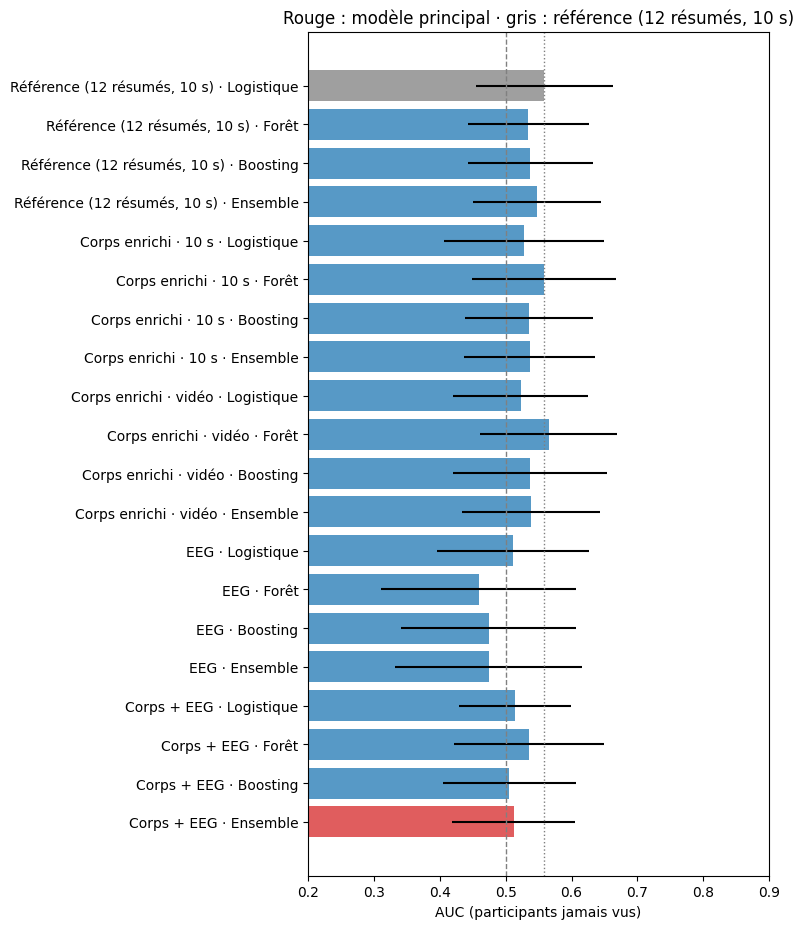

In [9]:
MODEL_ORDER = ["Logistique", "Forêt", "Boosting", "Ensemble"]
SET_ORDER = list(FEATURE_SETS)
for metric in ["AUC", "balanced accuracy"]:
    table = scores[scores.modèle != "Classe majoritaire"].pivot_table(
        index="features", columns="modèle", values=metric, aggfunc="mean").reindex(index=SET_ORDER, columns=MODEL_ORDER)
    print(f"{metric} moyenne (classe majoritaire : "
          f"{scores.loc[scores.modèle == 'Classe majoritaire', metric].mean():.3f})")
    display(table.round(3))

n_participants = scores.participant.nunique()
main_v, ref_v = " · ".join(MAIN), " · ".join(REFERENCE)
summary = scores.groupby("version")[["AUC", "balanced accuracy"]].agg(["mean", "std"])
print(f"\nModèle principal ({main_v}) : AUC {summary.loc[main_v, ('AUC', 'mean')]:.3f} "
      f"± {summary.loc[main_v, ('AUC', 'std')]:.3f} ; référence : {summary.loc[ref_v, ('AUC', 'mean')]:.3f} "
      f"± {summary.loc[ref_v, ('AUC', 'std')]:.3f} ; {n_participants} participants.")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(SET_ORDER) * 4 + 1))
plot_rows = [f"{s} · {m}" for s in SET_ORDER for m in MODEL_ORDER]
means = summary.reindex(plot_rows)[("AUC", "mean")]
stds = summary.reindex(plot_rows)[("AUC", "std")]
colors = ["tab:red" if r == main_v else "tab:gray" if r == ref_v else "tab:blue" for r in plot_rows]
ax.barh(plot_rows, means, xerr=stds, color=colors, alpha=0.75)
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.axvline(summary.loc[ref_v, ("AUC", "mean")], color="tab:gray", ls=":", lw=1)
ax.set(xlabel="AUC (participants jamais vus)", xlim=(0.2, 0.9),
       title="Rouge : modèle principal · gris : référence (12 résumés, 10 s)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 5.1 · Comparaisons participant par participant

Chaque ligne isole **un seul changement**, pour savoir ce qui aide :

1. modèle principal contre référence (le résultat global) ;
2. features riches, même fenêtre de 10 s, même modèle (effet des features) ;
3. toute la vidéo contre 10 s, mêmes features (effet de la fenêtre) ;
4. ajouter l'EEG au corps (effet de l'EEG) ;
5. ensemble contre régression logistique, mêmes features (effet du modèle).

Comme avant : si l'intervalle de confiance contient 0, on ne peut pas conclure.

In [10]:
def paired_table(table, pairs, metric, n_boot=5000, seed=0):
    wide = table.pivot(index="participant", columns="version", values=metric)
    rng_b = np.random.default_rng(seed)
    out = []
    for a, b in pairs:
        if a not in wide or b not in wide:
            continue
        d = (wide[a] - wide[b]).dropna().to_numpy()
        boot = [rng_b.choice(d, size=len(d), replace=True).mean() for _ in range(n_boot)]
        p = wilcoxon(d).pvalue if np.any(d != 0) and len(d) >= 5 else np.nan
        out.append({"A": a, "B": b, "victoires de A": f"{int((d > 0).sum())} / {len(d)}",
                    "différence moyenne": d.mean(), "IC 95 % bas": np.percentile(boot, 2.5),
                    "IC 95 % haut": np.percentile(boot, 97.5), "p (Wilcoxon)": p})
    return pd.DataFrame(out).round(3)


COMPARISONS = [
    (main_v, ref_v),
    ("Corps enrichi · 10 s · Logistique", ref_v),
    ("Corps enrichi · vidéo · Logistique", "Corps enrichi · 10 s · Logistique"),
    ("Corps + EEG · Ensemble", "Corps enrichi · vidéo · Ensemble"),
    ("EEG · Ensemble", "Corps enrichi · vidéo · Ensemble"),
    ("Corps + EEG · Ensemble", "Corps + EEG · Logistique"),
    ("Corps enrichi · vidéo · Ensemble", "Corps enrichi · vidéo · Logistique"),
]
for metric in ["AUC", "balanced accuracy"]:   # mesure principale d'abord
    print(f"\nMesure : {metric}")
    display(paired_table(scores, COMPARISONS, metric))


Mesure : AUC


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,Corps + EEG · Ensemble,"Référence (12 résumés, 10 s) · Logistique",9 / 26,-0.046,-0.088,-0.001,0.013
1,Corps enrichi · 10 s · Logistique,"Référence (12 résumés, 10 s) · Logistique",9 / 26,-0.031,-0.067,0.002,0.104
2,Corps enrichi · vidéo · Logistique,Corps enrichi · 10 s · Logistique,12 / 26,-0.005,-0.021,0.011,0.819
3,Corps + EEG · Ensemble,Corps enrichi · vidéo · Ensemble,12 / 26,-0.026,-0.072,0.014,0.532
4,EEG · Ensemble,Corps enrichi · vidéo · Ensemble,10 / 26,-0.065,-0.133,0.004,0.089
5,Corps + EEG · Ensemble,Corps + EEG · Logistique,13 / 26,-0.002,-0.034,0.031,0.851
6,Corps enrichi · vidéo · Ensemble,Corps enrichi · vidéo · Logistique,15 / 26,0.016,-0.020,0.052,0.408



Mesure : balanced accuracy


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,Corps + EEG · Ensemble,"Référence (12 résumés, 10 s) · Logistique",7 / 26,-0.029,-0.068,0.011,0.121
1,Corps enrichi · 10 s · Logistique,"Référence (12 résumés, 10 s) · Logistique",11 / 26,-0.030,-0.071,0.010,0.253
2,Corps enrichi · vidéo · Logistique,Corps enrichi · 10 s · Logistique,12 / 26,0.009,-0.011,0.029,0.381
3,Corps + EEG · Ensemble,Corps enrichi · vidéo · Ensemble,13 / 26,-0.015,-0.053,0.024,0.600
4,EEG · Ensemble,Corps enrichi · vidéo · Ensemble,13 / 26,-0.044,-0.099,0.013,0.328
5,Corps + EEG · Ensemble,Corps + EEG · Logistique,10 / 26,0.001,-0.036,0.041,0.777
6,Corps enrichi · vidéo · Ensemble,Corps enrichi · vidéo · Logistique,16 / 26,0.007,-0.039,0.051,0.619


## 6 · Quelles features comptent ?

Importance moyenne de chaque feature dans la forêt aléatoire du jeu « Corps + EEG », sur tous les plis, puis la somme par signal. C'est **descriptif** : une feature importante est utilisée par le modèle, ce qui ne prouve pas qu'elle cause l'arousal.

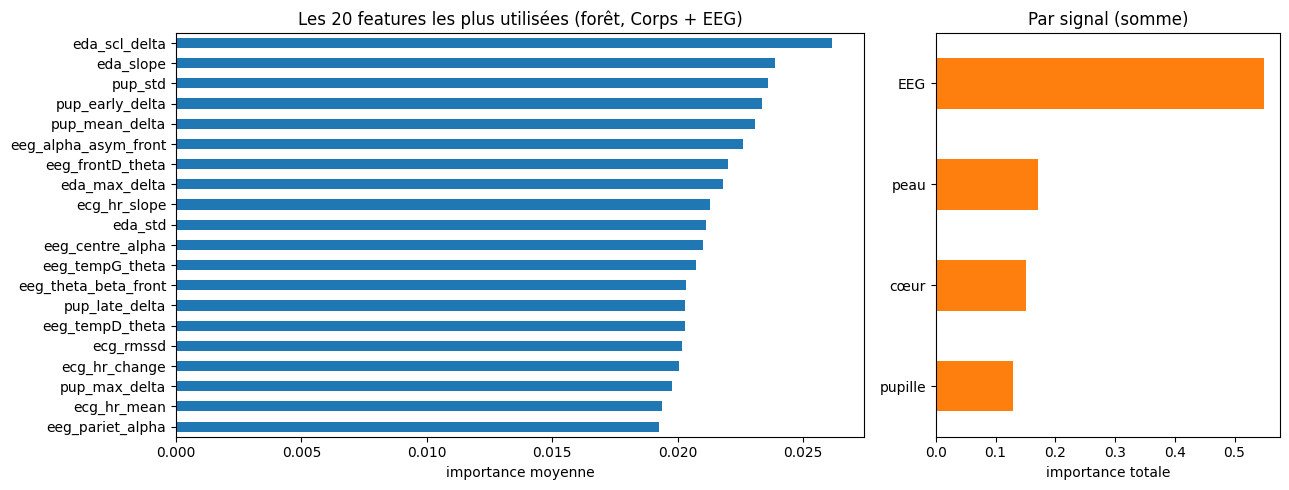

In [11]:
if importances:
    imp = pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
    imp.head(20)[::-1].plot.barh(ax=axes[0], color="tab:blue")
    axes[0].set(title="Les 20 features les plus utilisées (forêt, Corps + EEG)", xlabel="importance moyenne")
    by_signal = imp.groupby(lambda c: {"ecg": "cœur", "eda": "peau", "resp": "respiration",
                                       "pup": "pupille", "eeg": "EEG"}[c.split("_")[0]]).sum().sort_values()
    by_signal.plot.barh(ax=axes[1], color="tab:orange")
    axes[1].set(title="Par signal (somme)", xlabel="importance totale")
    plt.tight_layout()
    plt.show()

## 7 · Comment lire les résultats

**La question principale :** le modèle principal (ensemble, corps + EEG) bat-il la référence (12 résumés, 10 s) ? Première ligne de la section 5.1.

**Si oui, d'où vient le gain ?** Les lignes 2 à 5 de la section 5.1 isolent la fenêtre, les features, l'EEG et le modèle. C'est ce qu'il faut présenter : pas seulement « ça marche mieux », mais **pourquoi**.

**Si non :** le plafond vient de ce que les signaux contiennent sur l'arousal dans ce protocole. C'est un résultat, à présenter comme tel.

**À ne pas faire :** choisir après coup la meilleure case des tableaux et l'annoncer comme résultat. Il y a 20 cases : la meilleure est gonflée par le hasard. Le résultat annoncé est celui du modèle principal déclaré à l'avance ; les autres cases servent à comprendre.

**Limites :**

- La pupille dépend de la luminosité des vidéos, inconnue ici.
- Les mêmes vidéos reviennent chez plusieurs participants : un modèle peut en partie reconnaître la vidéo plutôt que la réaction.
- La standardisation utilise toutes les vidéos du participant testé (sans leurs notes).
- La fenêtre « vidéo entière » est plafonnée à `MAX_WINDOW_S` secondes.
- L'EEG est résumé par régions et par bandes : c'est une approximation simple de l'imagerie de source utilisée par Hou et al. (2024).